In [1]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
import joblib

RANDOM_STATE = 42
TEST_SIZE = 0.20
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
candidate_paths = [Path("raw_intents_data.csv"), Path("/mnt/data/raw_intents_data.csv")]
data_path = next((p for p in candidate_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Could not find raw_intents_data.csv. Upload it to the notebook's working directory "
        "or update candidate_paths to its location."
    )

df = pd.read_csv(data_path)
print(f"Loaded: {data_path.resolve()}")
print("Shape:", df.shape)
display(df.head())
display(df.tail())
print("\nColumn names:", df.columns.tolist())
df.info()
display(df.describe(include="all").T)

Loaded: C:\Users\MAGIC\raw_intents_data.csv
Shape: (837, 2)


,text,intent
0,open chrome,OPEN_APPLICATION
1,launch firefox,OPEN_APPLICATION
2,start vs code,OPEN_APPLICATION
3,run terminal,OPEN_APPLICATION
4,open the media player,OPEN_APPLICATION


,text,intent
832,make script test.py,CREATE_FILE
833,create python file script.py,CREATE_FILE
834,make a markdown readme file,CREATE_FILE
835,create file requirements.txt,CREATE_FILE
836,make a log file,CREATE_FILE



Column names: ['text', 'intent']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 837 entries, 0 to 836
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    837 non-null    object
 1   intent  837 non-null    object
dtypes: object(2)
memory usage: 13.2+ KB


,count,unique,top,freq
text,837,802,what day is today,3
intent,837,9,OPEN_APPLICATION,179


In [3]:
required_columns = {"text", "intent"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(
        f"Expected columns {sorted(required_columns)} based on inspection of this dataset; "
        f"missing: {sorted(missing_columns)}. Actual columns: {df.columns.tolist()}"
    )

print("Input feature: text (natural-language command)")
print("Target: intent (class to predict)")
print("Target classes:", sorted(df["intent"].dropna().astype(str).unique().tolist()))
print("Number of target classes:", df["intent"].nunique())

Input feature: text (natural-language command)
Target: intent (class to predict)
Target classes: ['CLOSE_APPLICATION', 'CREATE_FILE', 'CREATE_FOLDER', 'LIST_FILES', 'OPEN_APPLICATION', 'OPEN_FOLDER', 'SHOW_DATE_TIME', 'SYSTEM_INFO', 'UNKNOWN']
Number of target classes: 9


In [4]:
# Missing-value counts and percentages
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
display(missing_summary)

print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate text values:", int(df["text"].duplicated().sum()))
print("Blank text values:", int(df["text"].fillna("").astype(str).str.strip().eq("").sum()))
print("Blank intent values:", int(df["intent"].fillna("").astype(str).str.strip().eq("").sum()))

print("Data types:\n", df.dtypes)
text_lengths = df["text"].dropna().astype(str).str.split().str.len()
print("Word-count summary:\n", text_lengths.describe())

,missing_count,missing_percent
text,0,0.0
intent,0,0.0


Exact duplicate rows: 35
Duplicate text values: 35
Blank text values: 0
Blank intent values: 0
Data types:
 text      object
intent    object
dtype: object
Word-count summary:
 count    837.000000
mean       4.354839
std        1.088002
min        2.000000
25%        4.000000
50%        4.000000
75%        5.000000
max        9.000000
Name: text, dtype: float64


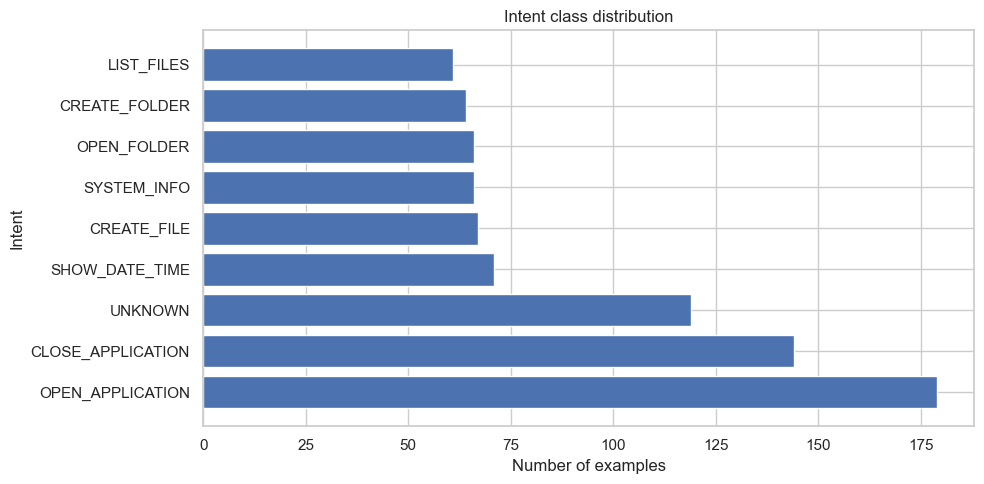

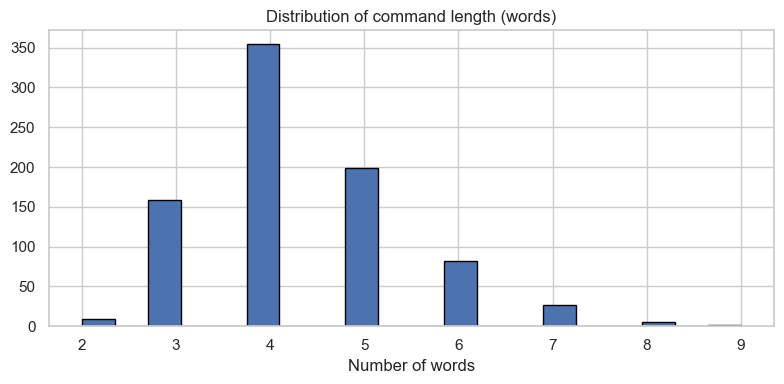

Class proportions (%):
 intent
OPEN_APPLICATION     21.39
CLOSE_APPLICATION    17.20
UNKNOWN              14.22
SHOW_DATE_TIME        8.48
CREATE_FILE           8.00
SYSTEM_INFO           7.89
OPEN_FOLDER           7.89
CREATE_FOLDER         7.65
LIST_FILES            7.29
Name: count, dtype: float64


In [5]:
plt.figure(figsize=(10, 5))
class_counts = df["intent"].value_counts()
plt.barh(class_counts.index, class_counts.values)
plt.title("Intent class distribution")
plt.xlabel("Number of examples")
plt.ylabel("Intent")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(text_lengths, bins=20, edgecolor="black")
plt.title("Distribution of command length (words)")
plt.xlabel("Number of words")
plt.tight_layout()
plt.show()

print("Class proportions (%):\n", (class_counts / len(df) * 100).round(2))

In [6]:
# Check whether identical text strings have conflicting labels
text_label_counts = df.dropna(subset=["text", "intent"]).groupby("text")["intent"].nunique()
conflicting_texts = text_label_counts[text_label_counts > 1]
print("Text strings associated with multiple intent labels:", len(conflicting_texts))
if len(conflicting_texts):
    display(df[df["text"].isin(conflicting_texts.index)].sort_values("text").head(30))

Text strings associated with multiple intent labels: 0


In [7]:
df_clean = df[["text", "intent"]].copy()
df_clean["text"] = df_clean["text"].astype("string").str.strip()
df_clean["intent"] = df_clean["intent"].astype("string").str.strip()
df_clean = df_clean.dropna(subset=["text", "intent"])
df_clean = df_clean[(df_clean["text"] != "") & (df_clean["intent"] != "")]
before_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=["text", "intent"]).reset_index(drop=True)
print("Rows before cleaning/deduplication:", len(df))
print("Rows after cleaning/deduplication:", len(df_clean))
print("Duplicate rows removed in this step:", before_dedup - len(df_clean))
print("Class counts after cleaning:\n", df_clean["intent"].value_counts())

# Same exact text with conflicting labels is not silently resolved.
conflicts_after_cleaning = df_clean.groupby("text")["intent"].nunique()
if (conflicts_after_cleaning > 1).any():
    raise ValueError("Some identical text examples have conflicting labels. Investigate these rows before training.")

Rows before cleaning/deduplication: 837
Rows after cleaning/deduplication: 802
Duplicate rows removed in this step: 35
Class counts after cleaning:
 intent
OPEN_APPLICATION     171
CLOSE_APPLICATION    137
UNKNOWN              115
SHOW_DATE_TIME        65
CREATE_FILE           64
OPEN_FOLDER           64
CREATE_FOLDER         63
SYSTEM_INFO           63
LIST_FILES            60
Name: count, dtype: Int64


In [8]:
X = df_clean["text"]
y = df_clean["intent"]
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of classes:", y.nunique())

# Keep the same split strategy across all four model notebooks.
# Stratification preserves approximate class proportions in train and test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Training class proportions:\n", y_train.value_counts(normalize=True).round(3))

X shape: (802,)
y shape: (802,)
Number of classes: 9
Training examples: 641
Testing examples: 161
Training class proportions:
 intent
OPEN_APPLICATION     0.214
CLOSE_APPLICATION    0.172
UNKNOWN              0.144
SHOW_DATE_TIME       0.081
OPEN_FOLDER           0.08
CREATE_FILE           0.08
CREATE_FOLDER        0.078
SYSTEM_INFO          0.078
LIST_FILES           0.075
Name: proportion, dtype: Float64


In [9]:
baseline_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2), sublinear_tf=True, max_features=5000)),
    ("classifier", MultinomialNB(alpha=1.0))
])

start = time.perf_counter()
baseline_pipeline.fit(X_train, y_train)
baseline_train_seconds = time.perf_counter() - start

start = time.perf_counter()
y_pred_baseline = baseline_pipeline.predict(X_test)
baseline_predict_seconds = time.perf_counter() - start
print(f"Baseline training time: {baseline_train_seconds:.3f} seconds")
print(f"Baseline prediction time: {baseline_predict_seconds:.4f} seconds")

Baseline training time: 0.018 seconds
Baseline prediction time: 0.0037 seconds


In [10]:
def evaluate_classifier(fitted_pipeline, X_eval, y_eval, label="Model"):
    predictions = fitted_pipeline.predict(X_eval)
    metrics = {
        "model": label,
        "accuracy": accuracy_score(y_eval, predictions),
        "precision_macro": precision_score(y_eval, predictions, average="macro", zero_division=0),
        "recall_macro": recall_score(y_eval, predictions, average="macro", zero_division=0),
        "f1_macro": f1_score(y_eval, predictions, average="macro", zero_division=0),
        "precision_weighted": precision_score(y_eval, predictions, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_eval, predictions, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y_eval, predictions, average="weighted", zero_division=0),
    }
    scores = None
    if hasattr(fitted_pipeline, "predict_proba"):
        scores = fitted_pipeline.predict_proba(X_eval)
    elif hasattr(fitted_pipeline, "decision_function"):
        scores = fitted_pipeline.decision_function(X_eval)
    if scores is not None:
        try:
            metrics["roc_auc_macro_ovr"] = roc_auc_score(
                y_eval, scores, labels=fitted_pipeline.classes_,
                multi_class="ovr", average="macro"
            )
        except (ValueError, TypeError):
            metrics["roc_auc_macro_ovr"] = np.nan
    else:
        metrics["roc_auc_macro_ovr"] = np.nan
    print(f"\n{label} metrics:")
    display(pd.DataFrame([metrics]).set_index("model").T.rename(columns={label: "score"}))
    print("\nClassification report:\n")
    print(classification_report(y_eval, predictions, zero_division=0))
    return metrics, predictions, scores

baseline_metrics, y_pred_baseline, baseline_scores = evaluate_classifier(
    baseline_pipeline, X_test, y_test, label="Baseline"
)


Baseline metrics:


model,score
accuracy,0.975155
precision_macro,0.988304
recall_macro,0.982823
f1_macro,0.984822
precision_weighted,0.977771
recall_weighted,0.975155
f1_weighted,0.975228
roc_auc_macro_ovr,0.998918



Classification report:

                   precision    recall  f1-score   support

CLOSE_APPLICATION       1.00      0.89      0.94        27
      CREATE_FILE       1.00      1.00      1.00        13
    CREATE_FOLDER       1.00      1.00      1.00        13
       LIST_FILES       1.00      1.00      1.00        12
 OPEN_APPLICATION       0.89      1.00      0.94        34
      OPEN_FOLDER       1.00      1.00      1.00        13
   SHOW_DATE_TIME       1.00      1.00      1.00        13
      SYSTEM_INFO       1.00      1.00      1.00        13
          UNKNOWN       1.00      0.96      0.98        23

         accuracy                           0.98       161
        macro avg       0.99      0.98      0.98       161
     weighted avg       0.98      0.98      0.98       161



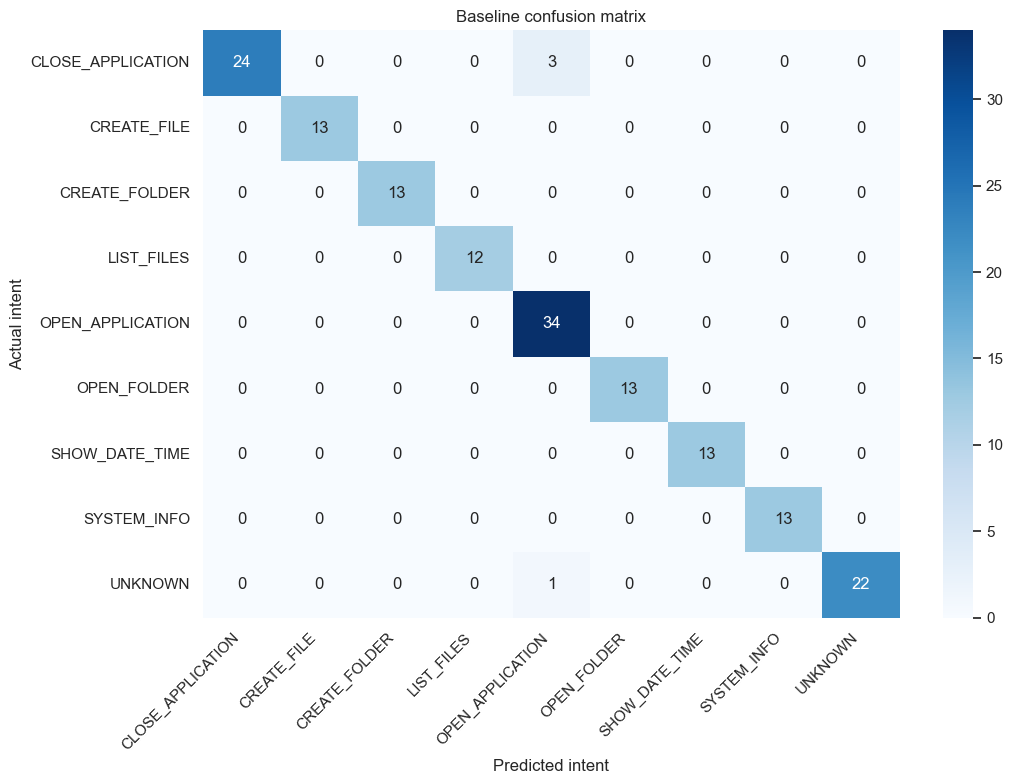

In [11]:
labels = baseline_pipeline.classes_
cm = confusion_matrix(y_test, y_pred_baseline, labels=labels)
plt.figure(figsize=(11, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Baseline confusion matrix")
plt.xlabel("Predicted intent")
plt.ylabel("Actual intent")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
param_grid = {"classifier__alpha": [0.1, 0.5, 1.0, 2.0]}
search = GridSearchCV(
    estimator=baseline_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1
)
start = time.perf_counter()
search.fit(X_train, y_train)
tuning_seconds = time.perf_counter() - start

print("Best cross-validation macro F1:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)
print(f"Grid-search time: {tuning_seconds:.2f} seconds")
best_pipeline = search.best_estimator_

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best cross-validation macro F1: 0.9659
Best parameters: {'classifier__alpha': 0.1}
Grid-search time: 0.28 seconds



Tuned model metrics:


model,score
accuracy,0.937888
precision_macro,0.948939
recall_macro,0.956374
f1_macro,0.951751
precision_weighted,0.938946
recall_weighted,0.937888
f1_weighted,0.937705
roc_auc_macro_ovr,0.998565



Classification report:

                   precision    recall  f1-score   support

CLOSE_APPLICATION       0.92      0.89      0.91        27
      CREATE_FILE       1.00      1.00      1.00        13
    CREATE_FOLDER       0.93      1.00      0.96        13
       LIST_FILES       1.00      1.00      1.00        12
 OPEN_APPLICATION       0.91      0.88      0.90        34
      OPEN_FOLDER       1.00      0.92      0.96        13
   SHOW_DATE_TIME       0.87      1.00      0.93        13
      SYSTEM_INFO       1.00      1.00      1.00        13
          UNKNOWN       0.91      0.91      0.91        23

         accuracy                           0.94       161
        macro avg       0.95      0.96      0.95       161
     weighted avg       0.94      0.94      0.94       161

Training accuracy of tuned model: 1.0000
Test accuracy of tuned model: 0.9379
Train-test accuracy gap: 0.0621


model,Baseline,Tuned model
accuracy,0.975155,0.937888
precision_macro,0.988304,0.948939
recall_macro,0.982823,0.956374
f1_macro,0.984822,0.951751
precision_weighted,0.977771,0.938946
recall_weighted,0.975155,0.937888
f1_weighted,0.975228,0.937705
roc_auc_macro_ovr,0.998918,0.998565


<Figure size 800x400 with 0 Axes>

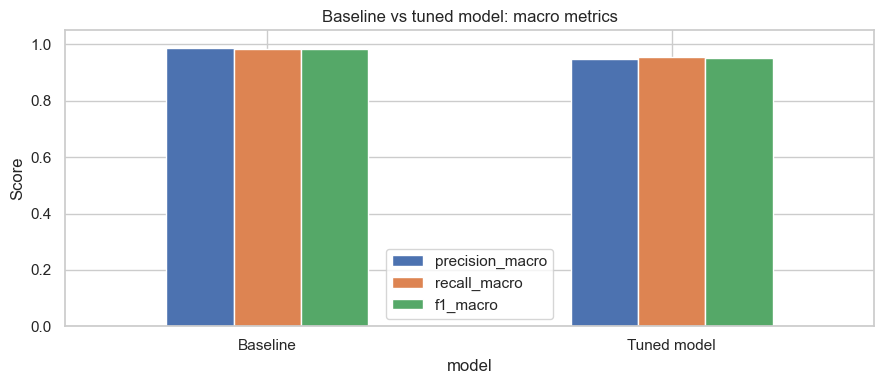

In [13]:
best_metrics, y_pred, y_scores = evaluate_classifier(
    best_pipeline, X_test, y_test, label="Tuned model"
)

train_accuracy = best_pipeline.score(X_train, y_train)
print(f"Training accuracy of tuned model: {train_accuracy:.4f}")
print(f"Test accuracy of tuned model: {best_metrics['accuracy']:.4f}")
print(f"Train-test accuracy gap: {train_accuracy - best_metrics['accuracy']:.4f}")

comparison = pd.DataFrame([baseline_metrics, best_metrics]).set_index("model")
display(comparison.T)

plt.figure(figsize=(8, 4))
comparison[["precision_macro", "recall_macro", "f1_macro"]].plot(kind="bar", figsize=(9, 4))
plt.title("Baseline vs tuned model: macro metrics")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

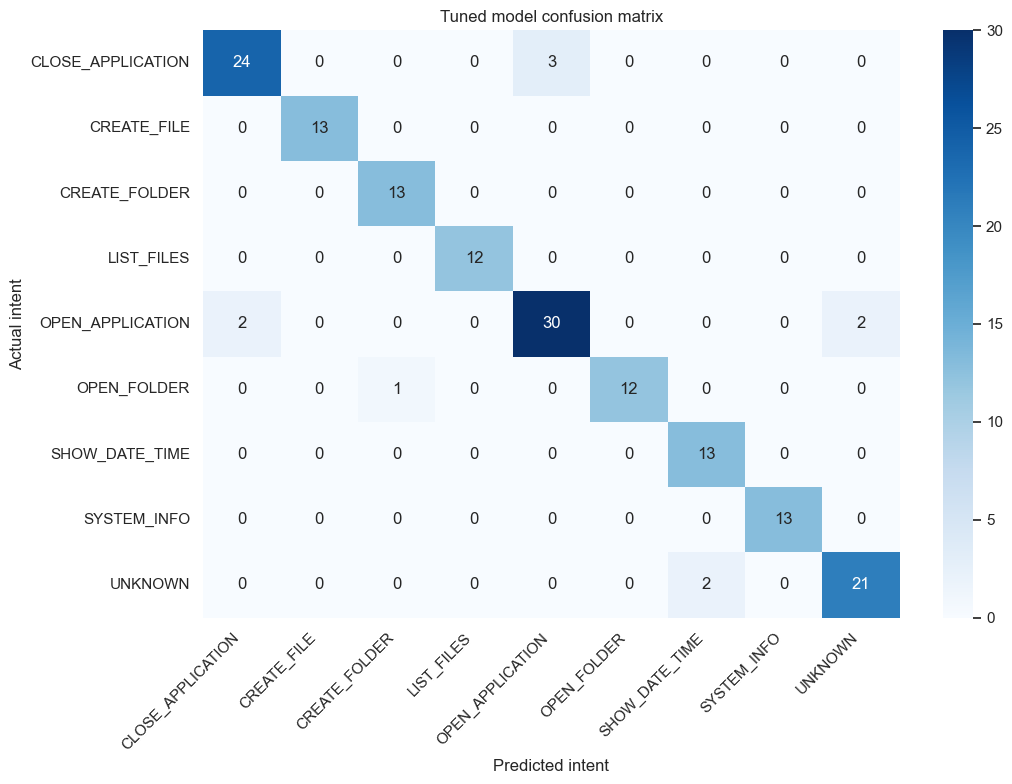

,actual,predicted,count
0,CLOSE_APPLICATION,OPEN_APPLICATION,3
1,OPEN_APPLICATION,CLOSE_APPLICATION,2
2,OPEN_APPLICATION,UNKNOWN,2
3,UNKNOWN,SHOW_DATE_TIME,2
4,OPEN_FOLDER,CREATE_FOLDER,1


In [14]:
labels = best_pipeline.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(11, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Tuned model confusion matrix")
plt.xlabel("Predicted intent")
plt.ylabel("Actual intent")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Show the most frequently confused actual -> predicted pairs, excluding correct predictions.
error_frame = pd.DataFrame({"actual": y_test.to_numpy(), "predicted": np.asarray(y_pred)})
error_frame = error_frame[error_frame["actual"] != error_frame["predicted"]]
if len(error_frame):
    display(error_frame.groupby(["actual", "predicted"]).size().sort_values(ascending=False).head(15).rename("count").reset_index())
else:
    print("No test-set misclassifications.")

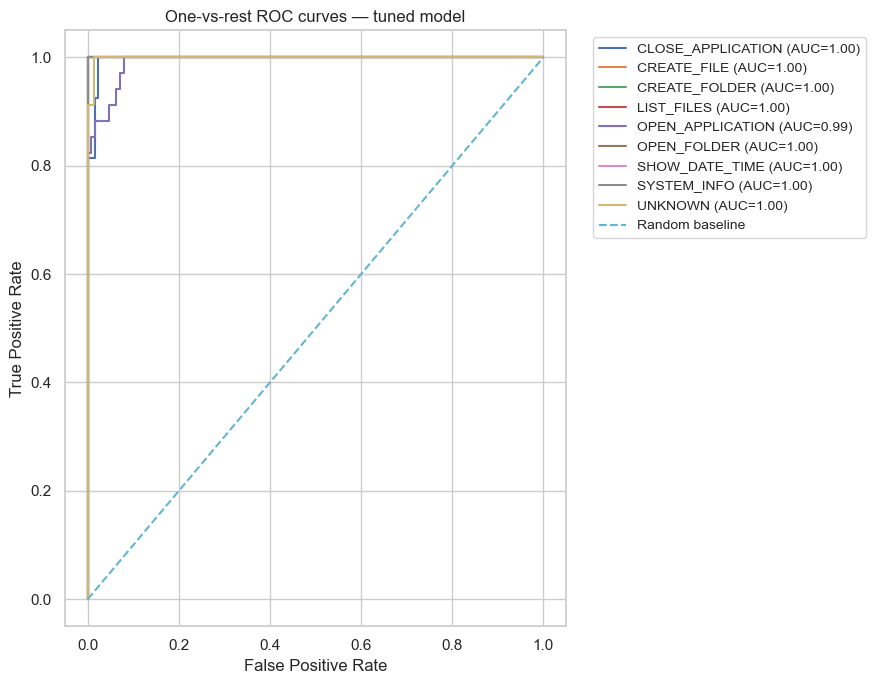

In [15]:
# Multiclass ROC curves using a one-vs-rest approach.
# Each curve treats one intent as positive and all other intents as negative.
if y_scores is not None and np.asarray(y_scores).ndim == 2 and np.asarray(y_scores).shape[1] == len(best_pipeline.classes_):
    y_test_binary = label_binarize(y_test, classes=best_pipeline.classes_)
    plt.figure(figsize=(9, 7))
    for class_index, class_name in enumerate(best_pipeline.classes_):
        fpr, tpr, _ = roc_curve(y_test_binary[:, class_index], np.asarray(y_scores)[:, class_index])
        class_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{class_name} (AUC={class_auc:.2f})")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
    plt.title("One-vs-rest ROC curves — tuned model")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left", fontsize="small")
    plt.tight_layout()
    plt.show()
else:
    print("ROC curves unavailable for this model/output configuration.")

In [16]:
vectorizer = best_pipeline.named_steps["tfidf"]
classifier = best_pipeline.named_steps["classifier"]
feature_names = vectorizer.get_feature_names_out()
print("Class log priors:")
display(pd.Series(classifier.class_log_prior_, index=classifier.classes_, name="class_log_prior"))
for class_index, class_name in enumerate(classifier.classes_):
    top_indices = np.argsort(classifier.feature_log_prob_[class_index])[-12:][::-1]
    print(f"\n{class_name}: terms with highest estimated likelihood")
    print(feature_names[top_indices].tolist())

Class log priors:


CLOSE_APPLICATION   -1.762549
CREATE_FILE         -2.531204
CREATE_FOLDER       -2.551006
LIST_FILES          -2.591828
OPEN_APPLICATION    -1.543049
OPEN_FOLDER         -2.531204
SHOW_DATE_TIME      -2.511786
SYSTEM_INFO         -2.551006
UNKNOWN             -1.941241
Name: class_log_prior, dtype: float64


CLOSE_APPLICATION: terms with highest estimated likelihood
['close', 'exit', 'chrome', 'browser', 'terminate', 'terminal', 'window', 'firefox', 'code', 'google', 'quit', 'settings']

CREATE_FILE: terms with highest estimated likelihood
['file', 'make', 'py', 'create', 'python', 'text', 'log', 'make python', 'script', 'create text', 'python file', 'json']

CREATE_FOLDER: terms with highest estimated likelihood
['create', 'folder', 'create folder', 'make', 'named', 'for', 'directory', 'make folder', 'folder named', 'make directory', 'directory for', 'files']

LIST_FILES: terms with highest estimated likelihood
['in', 'list', 'files', 'files in', 'all', 'list all', 'all files', 'show', 'display', 'folder', 'directory', 'items in']

OPEN_APPLICATION: terms with highest estimated likelihood
['open', 'start', 'launch', 'chrome', 'browser', 'code', 'firefox', 'player', 'terminal', 'settings', 'mozilla', 'app']

OPEN_FOLDER: terms with highest estimated likelihood
['folder', 'open', 'open fol

In [17]:
model_path = Path("naive_bayes_pipeline.joblib")
joblib.dump(best_pipeline, model_path)
print("Saved pipeline to:", model_path.resolve())

# Load it again and verify that predictions work.
loaded_pipeline = joblib.load(model_path)
print("Reloaded model test prediction sample:", loaded_pipeline.predict(X_test.iloc[:5]).tolist())

Saved pipeline to: C:\Users\MAGIC\naive_bayes_pipeline.joblib
Reloaded model test prediction sample: ['CLOSE_APPLICATION', 'SHOW_DATE_TIME', 'OPEN_APPLICATION', 'CREATE_FILE', 'CREATE_FILE']


In [18]:
new_commands = [
    "open chrome",
    "what time is it",
    "create a folder called research",
    "show system information",
    "play some relaxing music"
]
new_predictions = loaded_pipeline.predict(new_commands)
prediction_demo = pd.DataFrame({"new_text": new_commands, "predicted_intent": new_predictions})
display(prediction_demo)

if hasattr(loaded_pipeline, "predict_proba"):
    probabilities = loaded_pipeline.predict_proba(new_commands)
    confidence = probabilities.max(axis=1)
    prediction_demo["highest_class_probability"] = confidence
    display(prediction_demo)

,new_text,predicted_intent
0,open chrome,OPEN_APPLICATION
1,what time is it,SHOW_DATE_TIME
2,create a folder called research,CREATE_FOLDER
3,show system information,SYSTEM_INFO
4,play some relaxing music,UNKNOWN


,new_text,predicted_intent,highest_class_probability
0,open chrome,OPEN_APPLICATION,0.925370
1,what time is it,SHOW_DATE_TIME,0.997344
2,create a folder called research,CREATE_FOLDER,0.978073
3,show system information,SYSTEM_INFO,0.975703
4,play some relaxing music,UNKNOWN,0.989828
